In [ ]:
import json
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving detections.json to detections.json


In [ ]:
import json

file_name = list(uploaded.keys())[0]

with open(file_name, "r") as f:
    detections = json.load(f)

print("Detection data loaded successfully!")
print("Number of detections:", len(detections))

Detection data loaded successfully!
Number of detections: 273


In [ ]:
print("First detection:\n")

print(detections[0])

First detection:

{'x1': 436.7486267089844, 'y1': 503.5987243652344, 'x2': 465.2367248535156, 'y2': 560.85595703125, 'center_x': 450.99267578125, 'center_y': 532.2273559570312, 'width': 28.48809814453125, 'height': 57.257232666015625, 'confidence': 0.832038402557373, 'class_id': 0}


In [ ]:
total_products = len(detections)

print("Total detected products:", total_products)

Total detected products: 273


In [ ]:
from collections import Counter

class_counts = Counter(
    detection["class_id"]
    for detection in detections
)

print("Product count by class:\n")

for class_id, count in class_counts.items():
    print(f"Class {class_id}: {count}")

Product count by class:

Class 0: 273


In [ ]:
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

print("Detection count at different confidence thresholds:\n")

for threshold in thresholds:

    count = sum(
        1
        for detection in detections
        if detection["confidence"] >= threshold
    )

    print(f"Confidence >= {threshold:.2f}: {count} products")

Detection count at different confidence thresholds:

Confidence >= 0.30: 273 products
Confidence >= 0.40: 273 products
Confidence >= 0.50: 273 products
Confidence >= 0.60: 258 products
Confidence >= 0.70: 186 products
Confidence >= 0.80: 12 products
Confidence >= 0.90: 0 products


In [ ]:
CONFIDENCE_THRESHOLD = 0.50

filtered_detections = [
    detection
    for detection in detections
    if detection["confidence"] >= CONFIDENCE_THRESHOLD
]

print("Confidence threshold:", CONFIDENCE_THRESHOLD)
print("Products after filtering:", len(filtered_detections))

Confidence threshold: 0.5
Products after filtering: 273


In [ ]:
centers = np.array([
    [
        detection["center_x"],
        detection["center_y"]
    ]
    for detection in filtered_detections
])

print("Center coordinates shape:", centers.shape)

print("\nFirst 5 centers:")
print(centers[:5])

Center coordinates shape: (273, 2)

First 5 centers:
[[450.99267578 532.22735596]
 [224.14715576 655.1204834 ]
 [186.2489624  526.09777832]
 [161.31427002 526.55419922]
 [236.00518799 526.87561035]]


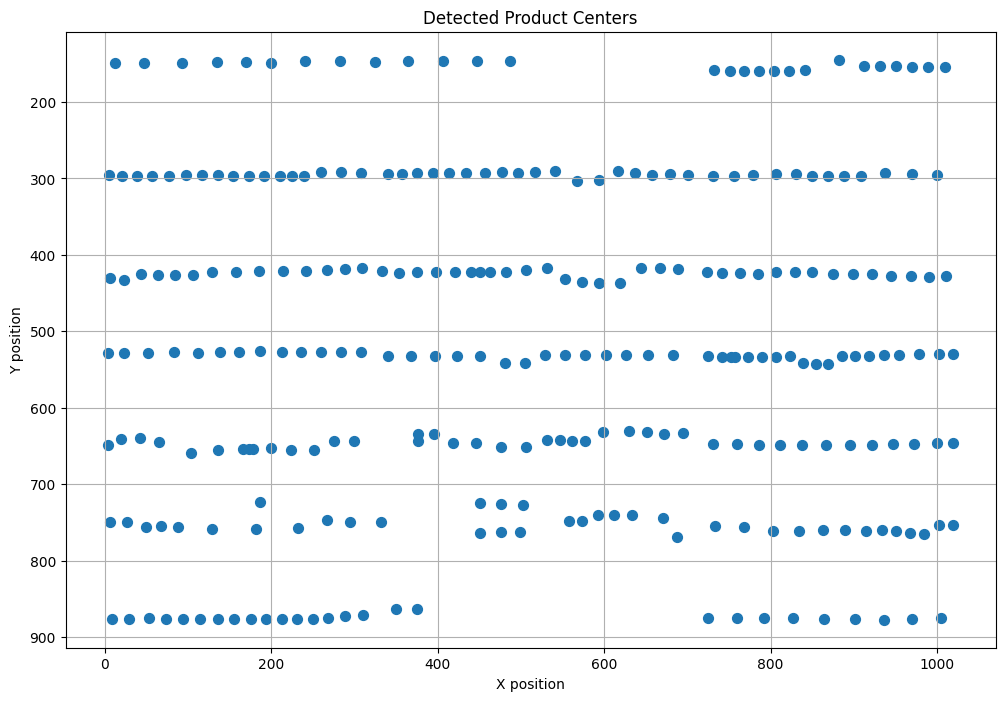

In [ ]:
plt.figure(figsize=(12, 8))

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    s=50
)

plt.gca().invert_yaxis()

plt.xlabel("X position")
plt.ylabel("Y position")
plt.title("Detected Product Centers")

plt.grid(True)
plt.show()

In [ ]:
sorted_detections = sorted(
    filtered_detections,
    key=lambda detection: detection["center_y"]
)

print("Products sorted from top to bottom.")

print("\nFirst 10 Y positions:")

for detection in sorted_detections[:10]:
    print(
        f"Y = {detection['center_y']:.1f}"
    )

Products sorted from top to bottom.

First 10 Y positions:
Y = 144.7
Y = 146.2
Y = 146.5
Y = 146.5
Y = 146.6
Y = 146.8
Y = 147.0
Y = 147.1
Y = 147.4
Y = 147.6


In [ ]:
def group_into_shelves(detections, y_threshold=50):

    detections_sorted = sorted(
        detections,
        key=lambda d: d["center_y"]
    )

    shelves = []

    for detection in detections_sorted:

        placed = False

        for shelf in shelves:

            average_y = np.mean([
                d["center_y"]
                for d in shelf
            ])

            if abs(
                detection["center_y"] - average_y
            ) <= y_threshold:

                shelf.append(detection)
                placed = True
                break

        if not placed:
            shelves.append([detection])

    # Sort each shelf left → right
    for shelf in shelves:
        shelf.sort(
            key=lambda d: d["center_x"]
        )

    return shelves
shelves = group_into_shelves(
    filtered_detections,
    y_threshold=50
)

print("Detected shelf rows:", len(shelves))

Detected shelf rows: 7


In [ ]:
print("Shelf-wise product count:\n")

for shelf_id, shelf in enumerate(shelves, start=1):

    print(
        f"Shelf {shelf_id}: "
        f"{len(shelf)} products"
    )

Shelf-wise product count:

Shelf 1: 27 products
Shelf 2: 47 products
Shelf 3: 46 products
Shelf 4: 46 products
Shelf 5: 42 products
Shelf 6: 38 products
Shelf 7: 27 products


In [ ]:
for shelf_id, shelf in enumerate(shelves, start=1):

    print(f"\nSHELF {shelf_id}")
    print("-" * 40)

    for product_id, detection in enumerate(
        shelf,
        start=1
    ):

        print(
            f"Product {product_id}: "
            f"x={detection['center_x']:.1f}, "
            f"y={detection['center_y']:.1f}, "
            f"confidence={detection['confidence']:.2f}"
        )


SHELF 1
----------------------------------------
Product 1: x=11.6, y=148.8, confidence=0.73
Product 2: x=47.5, y=148.6, confidence=0.70
Product 3: x=92.0, y=148.5, confidence=0.67
Product 4: x=134.3, y=147.6, confidence=0.69
Product 5: x=169.0, y=147.4, confidence=0.72
Product 6: x=200.1, y=148.4, confidence=0.73
Product 7: x=240.7, y=146.8, confidence=0.73
Product 8: x=282.9, y=146.2, confidence=0.73
Product 9: x=324.2, y=147.1, confidence=0.76
Product 10: x=364.6, y=147.0, confidence=0.74
Product 11: x=406.2, y=146.5, confidence=0.74
Product 12: x=447.5, y=146.6, confidence=0.72
Product 13: x=486.3, y=146.5, confidence=0.71
Product 14: x=732.2, y=158.6, confidence=0.62
Product 15: x=751.4, y=159.0, confidence=0.64
Product 16: x=768.4, y=159.2, confidence=0.61
Product 17: x=786.4, y=159.1, confidence=0.68
Product 18: x=804.5, y=159.1, confidence=0.64
Product 19: x=822.2, y=158.8, confidence=0.60
Product 20: x=841.3, y=158.8, confidence=0.53
Product 21: x=882.4, y=144.7, confidence=0

In [ ]:
uploaded_image = files.upload()

Saving self1.jpg to self1.jpg


In [ ]:
image_name = list(uploaded_image.keys())[0]

image = cv2.imread(
    os.path.join("/content", image_name)
)

image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

print("Image loaded successfully!")
print("Image size:", image.shape[1], "x", image.shape[0])

Image loaded successfully!
Image size: 1024 x 1024


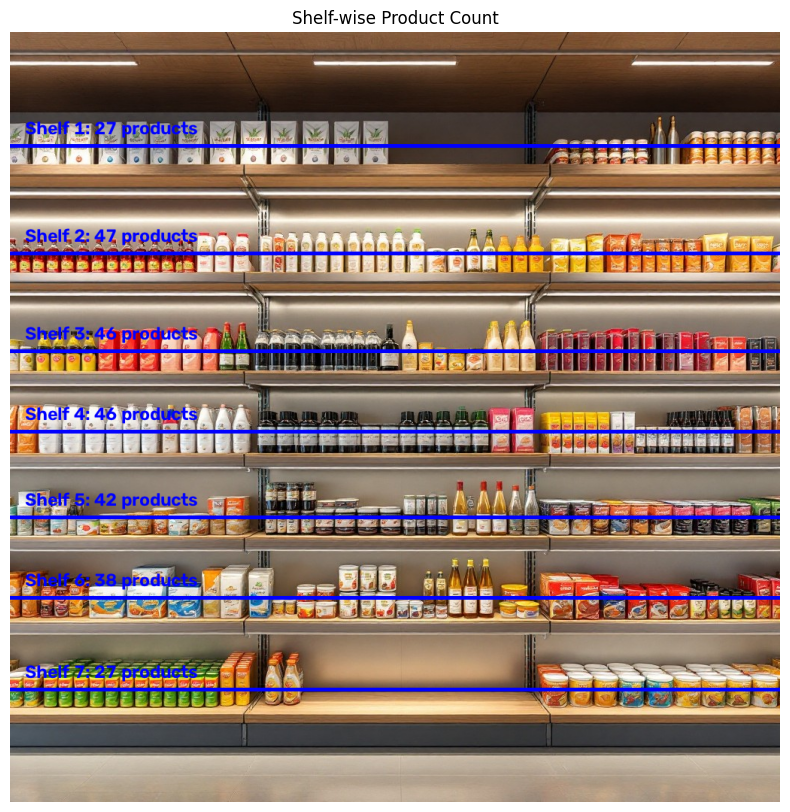

In [ ]:
visualized = image.copy()

for shelf_id, shelf in enumerate(
    shelves,
    start=1
):

    average_y = int(
        np.mean([
            d["center_y"]
            for d in shelf
        ])
    )

    # Draw shelf line
    cv2.line(
        visualized,
        (0, average_y),
        (visualized.shape[1], average_y),
        (255, 0, 0),
        3
    )

    # Shelf label
    label = (
        f"Shelf {shelf_id}: "
        f"{len(shelf)} products"
    )

    cv2.putText(
        visualized,
        label,
        (20, max(30, average_y - 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (255, 0, 0),
        2
    )

visualized_rgb = cv2.cvtColor(
    visualized,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(16, 10))
plt.imshow(visualized_rgb)
plt.axis("off")
plt.title("Shelf-wise Product Count")
plt.show()

In [ ]:
count_summary = {
    f"shelf_{i}": len(shelf)
    for i, shelf in enumerate(
        shelves,
        start=1
    )
}

print("COUNT SUMMARY")
print("=" * 30)

for shelf, count in count_summary.items():
    print(f"{shelf}: {count} products")

print("\nTotal:", sum(count_summary.values()))

COUNT SUMMARY
shelf_1: 27 products
shelf_2: 47 products
shelf_3: 46 products
shelf_4: 46 products
shelf_5: 42 products
shelf_6: 38 products
shelf_7: 27 products

Total: 273
